# Bölüm Özeti

Bu bölümde dikkat mekanizması(Attention mechanism) için gerekli olan metin verilerinin nasıl işlendiğini öğreneceğiz. 
- Neden dikkat mekanizmasına ihtiyaç duyulduğunu anlayacağız.
- Temel bir self-attention mekanizması uygulayacağız. Ardından daha karmaşık dikkat mekanizmalarına geçeceğiz.
- Dikkat mekanizmasının çeşitli uygulamalarını inceleyeceğiz.
- Multi-head attention ve transformer mimarisini keşfedeceğiz.

# Giriş
Önceki bölümlerde LLM için metin hazırlamanın temel adımlarını öğrendik. Metinlerin tokenlara ayrılması, gömme (embedding) işlemi ve pozisyonel kodlamalar gibi konuları ele aldık. Bu bölümde ise dikkat mekanizması(Attention mechanism) için gerekli olan metin verilerinin nasıl işlendiğini öğreneceğiz.

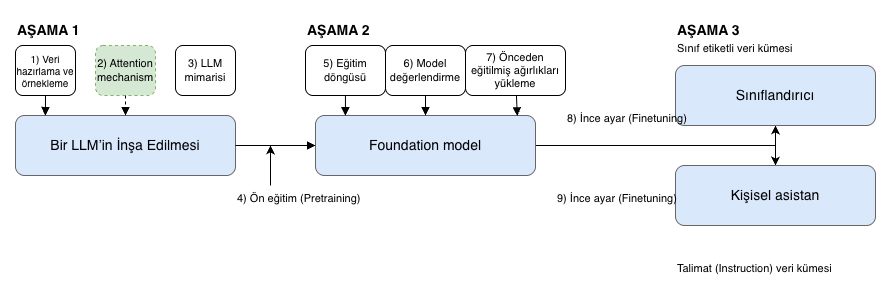

Attention mekanizması, özellikle doğal dil işleme (NLP) ve bilgisayarla görme (CV) gibi alanlarda devrim yaratan bir tekniktir. Transformer mimarisinin temel bileşeni olarak, modellerin uzun menzilli bağımlılıkları yakalamasına ve bağlamı daha iyi anlamasına olanak tanır. O nedenle bu bölümde dikkat mekanizmasını derinlemesine inceleyeceğiz.

Bu bölümde 4 farklı attention mekanizmasını ele alacağız:
1. Basitleştirilmiş Self-Attention
2. Self-Attention
3. Causal Self-Attention
4. Multi-Head Attention

## Uzun Sıralı Verilerin İşlenmesi ile İlgili Zorluklar
Uzun sıralı verilerle çalışırken, özellikle RNN ve LSTM gibi geleneksel modellerde çeşitli zorluklar ortaya çıkar. Bu zorluklar arasında şunlar bulunur:
- **Uzun Menzilli Bağımlılıklar**: Geleneksel modeller, uzun menzilli bağımlılıkları yakalamakta zorlanır. Bu, modelin önceki bilgilere dayalı olarak doğru tahminler yapmasını engeller.
- **Hafıza Kısıtlamaları**: Uzun sıralar, modelin belleğinde saklanması gereken daha fazla bilgi anlamına gelir, bu da hesaplama kaynaklarını zorlayabilir. 
- **Eğitim Zorlukları**: Uzun sıralar, eğitim sürecini yavaşlatabilir ve modelin öğrenme yeteneğini olumsuz etkileyebilir. Bu zorlukları aşmak için dikkat mekanizmaları geliştirilmiştir. Dikkat mekanizmaları, modelin önemli bilgilere odaklanmasını sağlar ve uzun menzilli bağımlılıkları daha etkili bir şekilde yakalamasına yardımcı olur.





## Basitleştirilmiş Self-Attention
Basitleştirilmiş self-attention mekanizması, temel bir dikkat mekanizmasıdır. Bu mekanizma ile başlamamızın amacı, dikkat mekanizmasının temel prensiplerini anlamaktır. Basitleştirilmiş self-attention, her bir tokenın diğer tokenlarla olan ilişkisini hesaplar ve bu ilişkileri kullanarak yeni bir temsil oluşturur.

self-attention mekanizmasının amacı bir bağlam vektörü oluşturmaktır. Bu bağlam vektörü, bir tokenın diğer tokenlarla olan ilişkisini temsil eder. 

$\text{Bağlam Vektörü} = \sum_{i=1}^{n} \alpha_i \cdot \text{Token}_i$

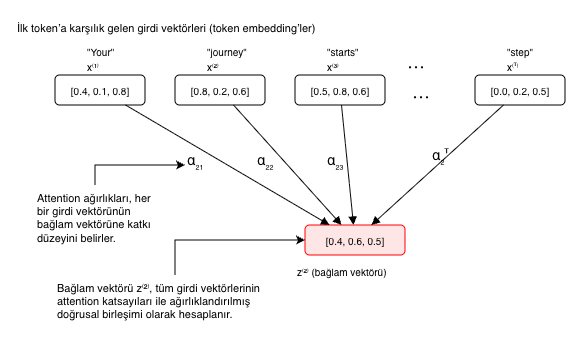

Görselde görüldüğü gibi T elamandan oluşan bir dizi tokenımız var. Herbir token $x^{(i)}$ bir vektör ile temsil ediliyor. Bu vektör d-boyutlu bir vektör bu örnekte 3 boyutlu. Amacımız her bir token için bir bağlam vektörü oluşturmak. Bağlam vektörü, o tokenın diğer tokenlarla olan ilişkisini temsil ediyor. Örneğin $x^{(2)}$ tokenı ("journey") için bağlam vektörünü $z^{(2)}$ hesaplayalım.

$$
\text{Bağlam vektörü } z^{(2)} = \alpha_{21} x^{(1)} + \alpha_{22} x^{(2)} + \alpha_{23} x^{(3)} + \alpha_{24} x^{(4)} + \alpha_{25} x^{(5)}
$$

In [ ]:
import torch

# Her satır bir token embedding'ini temsil eder: x^(1), x^(2), ..., x^(6)
inputs = torch.tensor([
    [0.43, 0.15, 0.89],  # Your        -> x^(1)
    [0.55, 0.87, 0.66],  # journey     -> x^(2)
    [0.57, 0.85, 0.64],  # starts      -> x^(3)
    [0.22, 0.58, 0.33],  # with        -> x^(4)
    [0.77, 0.25, 0.10],  # one         -> x^(5)
    [0.05, 0.80, 0.55],  # step        -> x^(6)
], dtype=torch.float32)

Girdi Tensörü Boyutu: torch.Size([4, 3])


In [10]:
# Sorgu (Query) olarak 1. kelimeyi seçelim: "Yolculuk"
query = inputs[0] # [1.0, 0.2, 0.5]
# Her kelime ile dot product hesaplayalım (Ham Skorlar)
# inputs matrisi ile query vektörünü çarpıyoruz.
attn_scores_2 = torch.matmul(inputs, query)
# Alternatif yazım: inputs @ query
print("Ham Dikkat Skorları:", attn_scores_2)

Ham Dikkat Skorları: tensor([1.2900, 0.4100, 0.9700, 0.6700])


- **Kendisiyle:** $e_{1,1} = [1.0, 0.2, 0.5] \cdot [1.0, 0.2, 0.5] = 1.29$
- **"Bir" ile:** $e_{1,2} = [1.0, 0.2, 0.5] \cdot [0.1, 0.8, 0.3] = 0.41$
- **"Adımla" ile:** $e_{1,3} = [1.0, 0.2, 0.5] \cdot [0.4, 0.6, 0.9] = 0.97$
- **"Başlar" ile:** $e_{1,4} = [1.0, 0.2, 0.5] \cdot [0.3, 0.1, 0.7] = 0.67$

Sonraki aşamada bu dikkat skorlarını normalize etmemiz gerekiyor ki bunlar birer ağırlık gösterebilsim. Amacımız toplamları 1 olan pozitif ağırlıklar elde etmek. Bunun için tüm skorlar için toplam skorları hesaplayıp her bir skoru bu toplam skora böleceğiz.
$$\alpha_{1i} = \frac{e_{1i}}{\sum_{j=1}^{T} e_{2j}}$$

In [11]:
# Toplam attention skoru
attn_scores_sum = attn_scores_2.sum()

# Normalize edilmiş attention ağırlıkları
attn_weights_2_tmp = attn_scores_2 / attn_scores_sum

print("Attention weights:", attn_weights_2_tmp)
print("Sum:", attn_weights_2_tmp.sum())

Attention weights: tensor([0.3862, 0.1228, 0.2904, 0.2006])
Sum: tensor(1.0000)


Ham skorlar:
$$
e_1 =[1.2900, 0.4100, 0.9700, 0.6700]
$$

Toplam:
$$
\sum e{1i} = 3.34
$$

Örnek:
$$
\alpha_{21} = \frac{0.41}{3.34} = \boxed{0.1228}
$$

Benzer şekilde diğerleri hesaplanır ve toplam tam olarak 1 çıkar.

Bu adımda elde edilen $\omega_{2i}$ değerleri normalize etmek için daha etkili bir yöntem olan Softmax fonksiyonunu kullanacağız. Softmax fonksiyonu:
- Tüm ağırlıkları pozitif yapar,
- Ağırlıkların toplamını 1’e eşitler,
- Görece büyük skorları daha baskın hâle getirir.

2. Matematiksel Tanım (Softmax Attention)

Ham attention skorları şu şekilde tanımlanır:
$$
\omega_{2i} = x^{(2)} \cdot x^{(i)}
$$

Softmax ile normalize edilmiş attention ağırlıkları:
$$
\alpha_{2i} = \frac{\exp(\omega_{2i})}{\sum_{j=1}^{T} \exp(\omega_{2j})}
$$

Bu tanım gereği:
$$
\sum_{i=1}^{T} \alpha_{2i} = 1
$$


In [12]:
import torch.nn.functional as F
attn_weights_2 = F.softmax(attn_scores_2, dim=0)
print(f"Normalize Ağırlıklar (alpha): {attn_weights_2}")
print(f"Toplam: {attn_weights_2.sum()}")

Normalize Ağırlıklar (alpha): tensor([0.3733, 0.1548, 0.2711, 0.2008])
Toplam: 1.0




Softmax uygulandıktan sonra:
- En büyük attention ağırlıkları, $x_1}$ ile en yüksek benzerliğe sahip vektörlere atanır.
- Küçük skorlar bastırılır ancak sıfıra eşitlenmez.
- Dağılım tamamen diferansiyellenebilirdir; bu da geri yayılım (backpropagation) ile öğrenmeye olanak tanır.

Transformer mimarisinde yaygın olarak kullanılan formül:
$$
\alpha_{1i} = \text{softmax}!\left(\frac{e_{1i}}{\sqrt{d}}\right)
$$
burada $d$, embedding boyutunu ifade eder (Vaswani et al., 2017).
- $\sqrt{d}$ ile ölçekleme:
- Büyük boyutlu embedding’lerde softmax’ın doygunluğa girmesini önler,
- Sayısal kararlılığı artırır.
- Bu örnekte $d = 3$ olduğu için ölçekleme eğitim amaçla ihmal edilmiştir.

olan bağlam vektörünü hesaplayabiliriz. Bağlam vektörü, her bir girdi vektörünün kendi dikkat ağırlığı ile çarpılıp toplanmasıyla elde edilir. Örneğin $x_1$ için bağlam vektörü $z_1$ şu şekilde hesaplanır:

$$z_1 = 0.373 \cdot x_1 + 0.155 \cdot x_2 + 0.271 \cdot x_3 + 0.200 \cdot x_4$$


In [13]:
context_vec_2 = torch.zeros(query.shape)
for i, x_i in enumerate(inputs):
	context_vec_2 += attn_weights_2[i] * x_i
print(f"Bağlam Vektörü z^(2): {context_vec_2}")

Bağlam Vektörü z^(2): tensor([0.5574, 0.3812, 0.6176])


In [5]:
import torch

# Sorgu vektörü: x^(2)
query = inputs[1]  # 2. input token query olarak seçilir

# Bağlam vektörü için başlangıç (sıfır vektörü)
context_vec_2 = torch.zeros(query.shape)

# z^(2) = sum_i alpha_{2i} * x^(i)
for i, x_i in enumerate(inputs):
    context_vec_2 += attn_weights_2[i] * x_i

print(context_vec_2)

tensor([0.4419, 0.6515, 0.5683])



Bu şekilde her bir token için bağlam vektörleri oluşturulur. Bu bağlam vektörleri, modelin her bir tokenın diğer tokenlarla olan ilişkisini anlamasına yardımcı olur ve böylece daha etkili bir şekilde öğrenmesini sağlar. Basitleştirilmiş self-attention mekanizması, dikkat mekanizmasının temel prensiplerini anlamak için iyi bir başlangıç noktasıdır. Daha karmaşık dikkat mekanizmalarına geçmeden önce bu temel prensipleri iyice kavramak önemlidir.

## Tüm tokenlar için Bağlam Vektörlerinin Hesaplanması
Şimdi tüm tokenler için bağlam vektörlerini hesaplayacağız. Her bir token için yukarıda açıklanan adımları tekrarlayarak bağlam vektörlerini elde edeceğiz. Öncelikle tüm tokenlar için dikkat skorlarını hesaplayacağız, ardından bu skorları softmax ile normalize edeceğiz ve son olarak bağlam vektörlerini oluşturacağız.

Adım 1: Tüm tokenlar için dikkat skorlarını hesaplayın.

$$
\omega_{ji} = x^{(j)} \cdot x^{(i)}
$$
burada $j$ sorgu tokenını, $i$ ise girdi tokenını temsil eder.


Adım 2: Her bir sorgu tokenı için softmax ile normalize edilmiş dikkat ağırlıklarını hesaplayın.
$$
\alpha_{ji} = \frac{\exp(\omega_{ji})}{\sum_{k=1}^{T} \exp(\omega_{jk})}
$$

Adım 3: Her bir sorgu tokenı için bağlam vektörlerini hesaplayın.
$$
z^{(j)} = \sum_{i=1}^{T} \alpha_{ji} \cdot x^{(i)}
$$  

## Adım 1

In [14]:
# Attention skor matrisi: Ω ∈ R^{T×T}
attn_scores = torch.empty(inputs.shape[0], inputs.shape[0])

# Tüm (i, j) çiftleri için noktasal çarpım
for i, x_i in enumerate(inputs):
    for j, x_j in enumerate(inputs):
        attn_scores[i, j] = torch.dot(x_i, x_j)

print(attn_scores)

tensor([[1.2900, 0.4100, 0.9700, 0.6700],
        [0.4100, 0.7400, 0.7900, 0.3200],
        [0.9700, 0.7900, 1.3300, 0.8100],
        [0.6700, 0.3200, 0.8100, 0.5900]])


Aşağıdaki ifade, self-attention mekanizmasındaki ham attention skor matrisini vektörleştirilmiş (loop’suz) biçimde hesaplar.

In [16]:
# Ham self-attention skor matrisi: Ω = X X^T
attn_scores = inputs @ inputs.T

print(attn_scores)

tensor([[1.2900, 0.4100, 0.9700, 0.6700],
        [0.4100, 0.7400, 0.7900, 0.3200],
        [0.9700, 0.7900, 1.3300, 0.8100],
        [0.6700, 0.3200, 0.8100, 0.5900]])


Girdi embedding matrisi
$$
X \in \mathbb{R}^{T \times d}
$$

Ham attention skor matrisi
$$
\Omega = X X^\top \in \mathbb{R}^{T \times T}
$$

Matrisin her bir elemanı
$$
\omega_{ij} = x^{(i)} \cdot x^{(j)}
$$


3. Boyutsal Doğrulama
- inputs boyutu: $(T \times d) = (6 \times 3)$
- inputs.T boyutu:$(d \times T) = (3 \times 6)$
- attn_scores boyutu:$(T \times T) = (6 \times 6)$


Yorum (Önemli Noktalar)
- Her satır $i$, sorgu token’ı $x^{(i)}$ için tüm anahtar token’lara karşılık gelen attention skorlarını içerir.
- Köşegen elemanlar $\omega_{ii}$, bir token’ın kendisiyle olan benzerliğini gösterir.
Bu matris:
- Normalize edilmemiştir,
- Henüz softmax uygulanmamıştır,
- Doğrudan olasılık yorumu yapılamaz.

## Adım 2

Tüm sorgu tokenları için softmax ile normalize edilmiş dikkat ağırlıklarını hesaplayalım. Bunun için PyTorch’un `softmax` fonksiyonunu kullanacağız. Bu fonksiyon, belirtilen boyut boyunca softmax işlemini gerçekleştirir. Bizim durumumuzda, her satırın (sorgu tokenı için) softmax ile normalize edilmesi gerekiyor, bu yüzden `dim=1` parametresini kullanacağız.

In [17]:
attn_weights = torch.softmax(attn_scores, dim=1)
print(attn_weights)

tensor([[0.3733, 0.1548, 0.2711, 0.2008],
        [0.2098, 0.2918, 0.3067, 0.1917],
        [0.2427, 0.2027, 0.3478, 0.2068],
        [0.2647, 0.1865, 0.3045, 0.2443]])


In [18]:
# Tüm satırların toplamı 1 olmalı
print(attn_weights.sum(dim=1))

tensor([1.0000, 1.0000, 1.0000, 1.0000])


## Adım 3

Şimdi dikkat ağırlıklarını kullanarak matris çarpımı yaparak bağlam vektörlerini hesaplayalım. Bu işlem, her bir sorgu tokenı için dikkat ağırlıkları ile girdi tokenlarının çarpımını ve toplanmasını içerir.

In [19]:
all_context_vectors = attn_weights @ inputs
print(all_context_vectors)

tensor([[0.5574, 0.3812, 0.6176],
        [0.4192, 0.4786, 0.6027],
        [0.4641, 0.4401, 0.6400],
        [0.4784, 0.4093, 0.6333]])


In [21]:
# Önceden bulduğumuz 2. bağlam vektörü ile karşılaştıralım
print("1. bağlam vektörü (döngü ile):", context_vec_2)
print("1. bağlam vektörü (matris çarpımı ile):", all_context_vectors[0])

1. bağlam vektörü (döngü ile): tensor([0.5574, 0.3812, 0.6176])
1. bağlam vektörü (matris çarpımı ile): tensor([0.5574, 0.3812, 0.6176])


Görüldüğü gibi, matris çarpımı kullanarak tüm bağlam vektörlerini tek seferde hesaplayabiliyoruz. Böylece basitleştirilmiş self-attention mekanizmasını vektörleştirilmiş biçimde uygulamış olduk. Bu yöntem, özellikle uzun dizilerle çalışırken hesaplama verimliliğini artırır ve kodun okunabilirliğini geliştirir. Ancak bu basitleştirilmiş versiyon, gerçek dünya uygulamalarında kullanılan self-attention mekanizmalarının tam gücünü yansıtmaz. Bunun yerine eğitilebilir ağırlık matrisleri kullanmamız gerekir. 

# Eğitilebilir Ağırlık Matrisleri
Basitleştirilmiş self-attention mekanizmasında, sorgu ve anahtar vektörleri doğrudan giriş embeddinglerinden türetilmiştir. Ancak gerçek dünya uygulamalarında, bu vektörlerin eğitilebilir ağırlık matrisleri kullanılarak oluşturulması gerekir. Bu, modelin dikkat mekanizmasını öğrenmesine ve optimize etmesine olanak tanır. Bağlam matrislerinin daha iyi sonuçlar vermesi için model içerisinde güncellenerek öğrenmesi sağlanır. 

Eğitilebilir ağırlık matrisleri kullanılarak sorgu, anahtar ve değer vektörleri oluşturulur:
$$
Q = X W_Q, \quad K = X W_K, \quad V = X W_V
$$
burada $W_Q$, $W_K$ ve $W_V$ sırasıyla sorgu, anahtar ve değer için eğitilebilir ağırlık matrisleridir. 

Daha önce yaptığımız gibi sadece 1. token için eğitilebilir ağırlık matrislerini hesaplayalım ve ardından bağlam vektörünü elde edelim.


In [23]:
import torch.nn as nn
d_in = inputs.shape[1] # Giriş boyutu: 3
d_out = 2 # Çıkış boyutu (Key/Query boyutu): 2 olsun
# Ağırlık matrislerini rastgele başlatıyoruz (Eğitimde bunlar güncellenir)
W_query = nn.Parameter(torch.rand(d_in, d_out))
W_key = nn.Parameter(torch.rand(d_in, d_out))
W_value = nn.Parameter(torch.rand(d_in, d_out))
# Girdileri Q, K, V uzaylarına izdüşürelim (Projection)
keys = inputs @ W_key
queries = inputs @ W_query
values = inputs @ W_value
print("Keys Boyutu:", keys.shape)

Keys Boyutu: torch.Size([4, 2])


Sonraki adımda tüm tokenlar için eğitilebilir ağırlık matrislerini kullanarak bağlam vektörlerini hesaplayacağız. Bu adımlar, basitleştirilmiş self-attention mekanizmasında yaptıklarımızla paralel olacaktır, ancak bu sefer sorgu, anahtar ve değer vektörleri eğitilebilir ağırlık matrisleri kullanılarak oluşturulacaktır.

In [24]:
# 1. Matris Çarpımı (Q x K^T)
# keys.T (Transpose) işlemi boyutları [2, 4] yapar.
# Sonuç [4, 4] boyutunda bir "benzerlik matrisi" olur.
attn_scores = queries @ keys.T
# 2. Ölçekleme (Scaling)
# Key vektörünün boyutunun kareköküne bölüyoruz.
d_k = keys.shape[-1]
attn_scores = attn_scores / (d_k ** 0.5)
# 3. Normalizasyon (Softmax)
# dim=-1 satır bazında (her kelime için) toplamın 1 olmasını sağlar.
attn_weights = torch.softmax(attn_scores, dim=-1)
# 4. Bağlam Vektörleri (Ağırlıklar x Value)
context_vecs = attn_weights @ values
print("Tüm Cümlenin Bağlam Vektörleri:\n", context_vecs)

Tüm Cümlenin Bağlam Vektörleri:
 tensor([[1.1262, 1.0750],
        [1.1218, 1.0710],
        [1.1363, 1.0841],
        [1.1119, 1.0622]], grad_fn=<MmBackward0>)


Matris çarpımı kullanarak tüm keys ve values vektörlerini hesaplayalım.

In [25]:
keys = inputs @ W_key
values = inputs @ W_value
print("Keys:\n", keys)
print("Values:\n", values)


Keys:
 tensor([[0.7577, 1.3662],
        [0.5405, 0.6837],
        [0.8380, 1.2197],
        [0.4778, 0.7487]], grad_fn=<MmBackward0>)
Values:
 tensor([[1.3900, 1.2741],
        [0.8219, 0.7754],
        [1.3408, 1.3113],
        [0.7839, 0.7878]], grad_fn=<MmBackward0>)


In [28]:
# Maske Oluşturma: Üst üçgeni 1 olan bir matris
# inputs.shape[0] = 4
context_length = attn_scores.shape[0]
mask = torch.triu(torch.ones(context_length, context_length), diagonal=1)
print("Maske:\n", mask)
# 1'ler geleceği, 0'lar geçmişi temsil eder.
# Maskeleme İşlemi:
# Maskenin 1 olduğu yerleri eksi sonsuz (-inf) ile doldururuz.
masked_scores = attn_scores.masked_fill(mask.bool(), -torch.inf)
print("\nMaskelenmiş Skorlar:\n", masked_scores)

Maske:
 tensor([[0., 1., 1., 1.],
        [0., 0., 1., 1.],
        [0., 0., 0., 1.],
        [0., 0., 0., 0.]])

Maskelenmiş Skorlar:
 tensor([[0.7255,   -inf,   -inf,   -inf],
        [0.6464, 0.3518,   -inf,   -inf],
        [0.9084, 0.5100, 0.8665,   -inf],
        [0.4844, 0.2792, 0.4693, 0.2797]], grad_fn=<MaskedFillBackward0>)


In [29]:
# Maskelenmiş skorlara softmax uygulama
attn_weights_masked = F.softmax(masked_scores, dim=-1)
print("\nMaskelenmiş Ağırlıklar:\n", attn_weights_masked)
# Dikkat ederseniz sağ üst üçgen tamamen 0 olmuştur.


Maskelenmiş Ağırlıklar:
 tensor([[1.0000, 0.0000, 0.0000, 0.0000],
        [0.5731, 0.4269, 0.0000, 0.0000],
        [0.3802, 0.2552, 0.3646, 0.0000],
        [0.2767, 0.2253, 0.2725, 0.2255]], grad_fn=<SoftmaxBackward0>)


# Multi-Head Attention

In [30]:
class MultiHeadAttentionWrapper(nn.Module):
    def __init__(self, d_in, d_out, context_length, dropout, num_heads, qkv_bias=False):
        super().__init__()
        # Her kafa için ayrı bir CausalAttention modülü oluşturulur
        self.heads = nn.ModuleList(
            [CausalAttention(d_in, d_out, context_length, dropout, qkv_bias) 
             for _ in range(num_heads)]
        )

    def forward(self, x):
        # Her kafanın çıktısını al ve son boyutta birleştir (cat)
        return torch.cat([head(x) for head in self.heads], dim=-1)

In [31]:
import numpy as np

def softmax(x, axis=-1):
    """Numerik kararlılık için geliştirilmiş Softmax fonksiyonu"""
    exp_x = np.exp(x - np.max(x, axis=axis, keepdims=True))
    return exp_x / np.sum(exp_x, axis=axis, keepdims=True)

def scaled_dot_product_attention_head(Q, K, V, mask=None):
    """
    Tek bir dikkat başlığı için scaled dot-product attention
    Q, K, V boyutu: (seq_len, d_k)
    """
    d_k = Q.shape[-1]
    
    # Dikkat skorları
    scores = np.matmul(Q, K.T) / np.sqrt(d_k)  # (seq_len, seq_len)
    
    # Maskeleme (causal attention için)
    if mask is not None:
        scores = scores + (mask * -1e9)
    
    # Softmax
    attn_weights = softmax(scores, axis=-1)  # (seq_len, seq_len)
    
    # Bağlam vektörleri
    output = np.matmul(attn_weights, V)  # (seq_len, d_k)
    
    return output, attn_weights

In [32]:
def multi_head_attention(X, W_Q_list, W_K_list, W_V_list, W_O, mask=None):
    """
    Naive Multi-head attention implementasyonu
    X boyutu: (seq_len, d_model)
    W_Q_list, ...: Ağırlık matrisleri listesi
    """
    num_heads = len(W_Q_list)
    heads = []
    
    for i in range(num_heads):
        # Her başlık için Query, Key, Value
        Q_i = np.matmul(X, W_Q_list[i])  # (seq_len, d_k)
        K_i = np.matmul(X, W_K_list[i])
        V_i = np.matmul(X, W_V_list[i])
        
        # Dikkat mekanizması
        head_output, _ = scaled_dot_product_attention_head(Q_i, K_i, V_i, mask)
        heads.append(head_output)
    
    # Başlıkları birleştir (Concatenate)
    concatenated = np.concatenate(heads, axis=-1)  # (seq_len, d_model)
    
    # Çıktı projeksiyonu
    output = np.matmul(concatenated, W_O)  # (seq_len, d_model)
    
    return output, heads

# Adım 1

In [39]:
import torch
import torch.nn as nn
import math

class AttentionHead(nn.Module):
    def __init__(self, emb_dim, d_h):
        super().__init__()
        # Eğitilebilir ağırlık matrisleri
        self.W_Q = nn.Parameter(torch.empty(emb_dim, d_h))
        self.W_K = nn.Parameter(torch.empty(emb_dim, d_h))
        self.W_V = nn.Parameter(torch.empty(emb_dim, d_h))
        self.d_h = d_h # Başlık boyutu

    def forward(self, x, mask):
        # 1. Q, K, V hesapla: (batch, seq_len, d_h)
        Q = x @ self.W_Q 
        K = x @ self.W_K
        V = x @ self.W_V
        
        # 2. RoPE uygula (Daha önce tanımladığımız fonksiyon)
        # Q, K = rope(Q), rope(K) # Not: RoPE fonksiyonu harici eklenebilir.

        # 3. Dikkat Skorlarını Hesapla
        # K'nın son iki boyutunu takas et (transpose) ki çarpım yapılabilsin.
        # Ölçeklendirme (scaling) için karekök d_h'a böl.
        scores = (Q @ K.transpose(-2, -1)) / math.sqrt(self.d_h)

        # 4. Maskeleme (Geleceği Gizle)
        # Maskenin 0 olduğu yerleri -sonsuz yap.
        masked_scores = scores.masked_fill(mask == 0, float("-inf"))

        # 5. Softmax ile Olasılıklara Dönüştür
        attention_weights = torch.softmax(masked_scores, dim=-1)

        # 6. Değerlerle (V) Çarp ve Sonucu Döndür
        return attention_weights @ V

2. Adım: Çok Başlı Dikkat (Multi-Head Attention)
Tek bir kafa yetmez. Farklı dilsel özellikleri yakalamak için birden fazla kafayı birleştiren MultiHeadAttention sınıfını yazalım.

In [40]:
class MultiHeadAttention(nn.Module):
    def __init__(self, emb_dim, num_heads):
        super().__init__()
        # Her kafanın boyutu: Toplam boyut / Kafa sayısı
        d_h = emb_dim // num_heads 
        
        # Kafaları bir liste (ModuleList) içinde sakla
        self.heads = nn.ModuleList([
            AttentionHead(emb_dim, d_h) for _ in range(num_heads)
        ])
        
        # Çıktıları birleştirdikten sonraki son projeksiyon matrisi
        self.W_O = nn.Parameter(torch.empty(emb_dim, emb_dim))

    def forward(self, x, mask):
        # 1. Her kafayı çalıştır
        head_outputs = [head(x, mask) for head in self.heads]
        
        # 2. Çıktıları yan yana birleştir (Concatenate)
        # Sonuç boyutu: (batch, seq_len, emb_dim)
        x = torch.cat(head_outputs, dim=-1)
        
        # 3. Son projeksiyonu uygula
        return x @ self.W_O

3. Adım: Konum Bazlı MLP (Feed Forward)
Dikkat mekanizmasından çıkan bilgiyi işlemek ve karmaşık kalıpları öğrenmek için bir MLP (Çok Katmanlı Algılayıcı) ekleriz. Genellikle boyutu önce genişletir (4 kat), sonra tekrar daraltırız.

In [41]:
class MLP(nn.Module):
    def __init__(self, emb_dim):
        super().__init__()
        # Boyutu 4 katına çıkar
        self.W_1 = nn.Parameter(torch.empty(emb_dim, emb_dim * 4))
        self.B_1 = nn.Parameter(torch.empty(emb_dim * 4))
        
        # Boyutu tekrar eski haline getir
        self.W_2 = nn.Parameter(torch.empty(emb_dim * 4, emb_dim))
        self.B_2 = nn.Parameter(torch.empty(emb_dim))

    def forward(self, x):
        # 1. Katman + Bias
        x = x @ self.W_1 + self.B_1
        # Aktivasyon Fonksiyonu (ReLU)
        x = torch.relu(x)
        # 2. Katman + Bias
        x = x @ self.W_2 + self.B_2
        return x

4. Adım: Decoder Bloğu (Tüm Parçaları Birleştirme)
Şimdi elimizdeki parçaları (Dikkat, MLP, Normalizasyon) birleştirerek Transformer'ın temel yapı taşı olan Decoder Bloğunu oluşturalım. Burada Artık Bağlantılar (Residual Connections) hayati önem taşır.

In [42]:
class DecoderBlock(nn.Module):
    def __init__(self, emb_dim, num_heads):
        super().__init__()
        self.norm1 = RMSNorm(emb_dim) # RMS Normalizasyonu
        self.attn = MultiHeadAttention(emb_dim, num_heads)
        self.norm2 = RMSNorm(emb_dim)
        self.mlp = MLP(emb_dim)

    def forward(self, x, mask):
        # 1. Adım: Dikkat Mekanizması + Artık Bağlantı
        # Girdiyi normalize et -> Dikkat'e sok -> Çıktıyı orijinal girdiyle topla
        attn_out = self.attn(self.norm1(x), mask)
        x = x + attn_out 
        
        # 2. Adım: MLP + Artık Bağlantı
        # Normalize et -> MLP'ye sok -> Çıktıyı önceki sonuçla topla
        mlp_out = self.mlp(self.norm2(x))
        x = x + mlp_out
        
        return x

In [45]:
import torch
import torch.nn as nn
import math
import torch.nn.functional as F

# Rastgelelik tohumu (Sonuçlar herkes için aynı olsun diye)
torch.manual_seed(42)

# --- 1. YARDIMCI KATMANLAR ---

class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, x):
        rms = torch.sqrt(torch.mean(x**2, dim=-1, keepdim=True) + self.eps)
        return (x / rms) * self.weight

class MLP(nn.Module):
    def __init__(self, emb_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(emb_dim, emb_dim * 4),
            nn.ReLU(),
            nn.Linear(emb_dim * 4, emb_dim)
        )
    def forward(self, x):
        return self.net(x)

# --- 2. DİKKAT MEKANİZMASI ---

class MultiHeadAttention(nn.Module):
    def __init__(self, emb_dim, num_heads, context_len):
        super().__init__()
        assert emb_dim % num_heads == 0, "Embedding boyutu kafa sayısına tam bölünmeli!"
        
        self.d_head = emb_dim // num_heads
        self.num_heads = num_heads
        
        # Q, K, V tek matriste (Hız için)
        self.W_q = nn.Linear(emb_dim, emb_dim, bias=False)
        self.W_k = nn.Linear(emb_dim, emb_dim, bias=False)
        self.W_v = nn.Linear(emb_dim, emb_dim, bias=False)
        self.W_o = nn.Linear(emb_dim, emb_dim, bias=False)
        
        # Causal Mask (Geleceği Gizle)
        self.register_buffer(
            "mask", 
            torch.tril(torch.ones(context_len, context_len)).view(1, 1, context_len, context_len)
        )

    def forward(self, x):
        B, T, C = x.shape # Batch, Time (Seq Len), Channels (Emb Dim)
        
        # Projeksiyonlar ve Kafalara Bölme
        # [B, T, C] -> [B, T, Num_Heads, Head_Dim] -> [B, Num_Heads, T, Head_Dim]
        Q = self.W_q(x).view(B, T, self.num_heads, self.d_head).transpose(1, 2)
        K = self.W_k(x).view(B, T, self.num_heads, self.d_head).transpose(1, 2)
        V = self.W_v(x).view(B, T, self.num_heads, self.d_head).transpose(1, 2)
        
        # Dikkat Skorları
        # (Q @ K_T) / sqrt(d_k)
        scores = (Q @ K.transpose(-2, -1)) / math.sqrt(self.d_head)
        
        # Maskeleme: Maskenin 0 olduğu yerleri -sonsuz yap
        # T boyutu dinamik olabilir, maskeyi kesiyoruz
        scores = scores.masked_fill(self.mask[:, :, :T, :T] == 0, float('-inf'))
        
        weights = F.softmax(scores, dim=-1)
        
        # Değerlerle Birleştirme
        out = weights @ V # [B, Heads, T, Head_Dim]
        
        # Kafaları Geri Birleştirme (Concat)
        out = out.transpose(1, 2).contiguous().view(B, T, C)
        
        return self.W_o(out)

# --- 3. DECODER BLOĞU ---

class DecoderBlock(nn.Module):
    def __init__(self, emb_dim, num_heads, context_len):
        super().__init__()
        self.norm1 = RMSNorm(emb_dim)
        self.attn = MultiHeadAttention(emb_dim, num_heads, context_len)
        self.norm2 = RMSNorm(emb_dim)
        self.mlp = MLP(emb_dim)

    def forward(self, x):
        # 1. Dikkat + Residual
        x = x + self.attn(self.norm1(x))
        # 2. MLP + Residual
        x = x + self.mlp(self.norm2(x))
        return x

# --- 4. ANA MODEL (GPT) ---

class MiniGPT(nn.Module):
    def __init__(self, vocab_size, emb_dim, num_heads, num_blocks, context_len):
        super().__init__()
        self.token_embedding = nn.Embedding(vocab_size, emb_dim)
        # Basitlik için öğrenilebilir konumsal embedding (Absolute Positional)
        self.pos_embedding = nn.Embedding(context_len, emb_dim)
        
        self.blocks = nn.Sequential(*[
            DecoderBlock(emb_dim, num_heads, context_len) for _ in range(num_blocks)
        ])
        
        self.final_norm = RMSNorm(emb_dim)
        self.lm_head = nn.Linear(emb_dim, vocab_size, bias=False)

    def forward(self, idx):
        B, T = idx.shape
        
        # Token + Konum Embeddingleri
        tok_emb = self.token_embedding(idx) # [B, T, Emb]
        pos_emb = self.pos_embedding(torch.arange(T, device=idx.device)) # [T, Emb]
        x = tok_emb + pos_emb
        
        # Transformer Blokları
        x = self.blocks(x)
        x = self.final_norm(x)
        
        # Tahmin (Logits)
        logits = self.lm_head(x) # [B, T, Vocab_Size]
        return logits

# --- 5. TEST EDELİM ---

# Hiperparametreler
VOCAB_SIZE = 1000 # Sözlük boyutu
EMB_DIM = 32      # Model boyutu (Küçük bir örnek)
NUM_HEADS = 4     # Kafa sayısı
NUM_BLOCKS = 2    # Katman sayısı
CONTEXT_LEN = 10  # Maksimum cümle uzunluğu

# Modeli oluştur
model = MiniGPT(VOCAB_SIZE, EMB_DIM, NUM_HEADS, NUM_BLOCKS, CONTEXT_LEN)

# Örnek Girdi: "Yolculuk bir adımla başlar" (Token ID'leri)
# Batch size = 1, Sequence length = 4
input_ids = torch.tensor([[42, 105, 12, 99]]) 

# Modeli çalıştır
logits = model(input_ids)

print(f"Girdi Boyutu: {input_ids.shape} -> [Batch, Time]")
print(f"Çıktı Boyutu: {logits.shape} -> [Batch, Time, Vocab_Size]")
print("\nModelin son kelime ('başlar') için ürettiği sonraki kelime tahmin skorları (ilk 5):")
print(logits[0, -1, :5])

Girdi Boyutu: torch.Size([1, 4]) -> [Batch, Time]
Çıktı Boyutu: torch.Size([1, 4, 1000]) -> [Batch, Time, Vocab_Size]

Modelin son kelime ('başlar') için ürettiği sonraki kelime tahmin skorları (ilk 5):
tensor([-0.1726,  1.2304, -0.5797, -0.1907,  0.8437], grad_fn=<SliceBackward0>)
